# MIT–BIT capacity and energy after a charging-rate switch

Forecast median discharge capacity in Ah and total delivered energy in Wh over the next five recorded aging cycles. Compare with Notebook 14 on the same measured blocks and held-out cells. Report all actions, both 2C↔3C directions, and same-rate blocks separately.

Run all cells from the project folder using the Python kernel. The Notebook 14 output folder or ZIP supplies every input. Model fitting uses one CPU thread. The Notebook 15 outputs are saved under reports.

In [1]:
import os
for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS",
             "VECLIB_MAXIMUM_THREADS", "BLIS_NUM_THREADS"):
    os.environ[name] = "1"

import json
from collections import defaultdict
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from threadpoolctl import threadpool_limits

INPUT_PATH = None  # Notebook 14 export folder or ZIP. Defaults to the project reports.
OUTPUT_ROOT = None
SOURCE_NAME = "lifeguard_mit_bit_switch_replay_results"
OUTPUT_NAME = "lifeguard_mit_bit_capacity_energy_results"
NOMINAL_AH = 2.4
BLOCK = 5
RATES = (1, 2, 3)
SWITCHES = ("2-to-3", "3-to-2")
GROUPS = ("all", *SWITCHES, "same-rate", "other-switch")
KEYS = ["cell_id", "start_cycle"]
TARGETS = {"capacity": {"unit": "Ah", "measured": "observed_ah", "baseline": "nb14_ah", "predicted": "predicted_ah"},
           "energy": {"unit": "Wh", "measured": "observed_wh", "baseline": "nb14_wh", "predicted": "predicted_wh"}}
ALPHAS = {"standard": (0.3, 1, 3, 10), "expanded": (1, 3, 10)}
RIDGES = tuple((family, alpha) for family, alphas in ALPHAS.items() for alpha in alphas)
BLEND = "blend_75_25"
ENERGY_FACTOR = "energy_factor"
BLEND_WEIGHT = 0.25

cwd = Path.cwd()
project = next((p for p in (cwd, *cwd.parents)
                if (p / "README_LifeGuard_RL.md").is_file() and (p / "reports").is_dir()), None)
if project is None:
    raise FileNotFoundError("Open this notebook from within the LifeGuard-RL project.")
source = Path(INPUT_PATH).expanduser() if INPUT_PATH is not None else project / "reports" / SOURCE_NAME
if INPUT_PATH is None and not source.is_dir():
    source = source.with_suffix(".zip")
output = (Path(OUTPUT_ROOT).expanduser() if OUTPUT_ROOT is not None else project / "reports") / OUTPUT_NAME

FILES = ("block_audit.csv", "cycle_audit.csv", "predictions.csv", "cell_splits.csv")


def read_exports(source):
    if source.is_dir():
        return [pd.read_csv(source / name) for name in FILES]
    if not source.is_file():
        raise FileNotFoundError(f"Expected the saved Notebook 14 report at {source}. Set INPUT_PATH if it moved.")
    tables = []
    with ZipFile(source) as bundle:
        for name in FILES:
            matches = [member for member in bundle.namelist() if Path(member).name == name]
            if len(matches) != 1:
                raise ValueError(f"Expected one {name} in {source}.")
            with bundle.open(matches[0]) as stream:
                tables.append(pd.read_csv(stream))
    return tables


def require_unique(table, keys, label):
    if table[keys].isna().any().any() or table.duplicated(keys).any():
        raise ValueError(f"Missing or duplicate keys in {label}: {keys}.")

## Measured targets and information at the forecast origin

Use the median of the five saved cycle capacities and the sum of all five meter-checked energy values. Keep the scoring masks from Notebook 14, including its prior-energy requirement. The nominal capacity percentage is 100 times Ah divided by 2.4 Ah. Use that same scale for the observed, Notebook 14, and new predictions.

At a forecast origin, read only preceding blocks and the next assigned charge rate. Preserve missing history for fold-local imputation. The Notebook 14 predictions serve as an evaluation reference.

In [2]:
def audited_blocks(blocks, cycles):
    require_unique(blocks, KEYS, "Notebook 14 block audit")
    require_unique(cycles, ["cell_id", "aging_cycle"], "Notebook 14 cycle audit")
    if not blocks.end_cycle.eq(blocks.start_cycle + BLOCK - 1).all():
        raise ValueError("Expected five-cycle blocks in Notebook 14.")

    raw = cycles.set_index(["cell_id", "aging_cycle"]).sort_index()
    observations = []
    for row in blocks.itertuples(index=False):
        window = raw.loc[row.cell_id].reindex(range(row.start_cycle, row.end_cycle + 1))
        capacity = window.capacity_ah
        delivered = window.delivered_wh
        equivalent_ah = window.integrated_ah
        # Score the same measured blocks as Notebook 14. The audit supplies their physical units.
        observed_ah = capacity.median() if capacity.notna().all() and pd.notna(row.observed_soh_pct) else np.nan
        observed_wh = delivered.sum() if delivered.notna().all() else np.nan
        total_ah = equivalent_ah.sum() if equivalent_ah.notna().all() and pd.notna(observed_wh) else np.nan
        observations.append((observed_ah, observed_wh, total_ah))
    table = blocks.copy()
    table[["observed_ah", "measured_wh", "total_integrated_ah"]] = observations
    np.testing.assert_allclose(table.observed_ah, table.observed_soh_pct * table.reference_ah / 100,
                               rtol=0, atol=1e-9)
    np.testing.assert_allclose(table.measured_wh, table.observed_wh, rtol=0, atol=1e-9)
    return table, raw.capacity_ah


def validate_folds(events, splits):
    require_unique(events, KEYS, "Notebook 14 predictions")
    require_unique(splits, ["fold", "cell_id"], "Notebook 14 cell splits")
    if set(splits.fold) != set(range(1, 6)) or events.cell_id.nunique() != 55:
        raise ValueError("Notebook 15 expects the full 55-cell, five-fold Notebook 14 benchmark.")
    test_fold = splits.loc[splits.role.eq("test")].set_index("cell_id", verify_integrity=True).fold
    cells = set(events.cell_id)
    if set(test_fold.index) != cells or not events.cell_id.map(test_fold).eq(events.fold).all():
        raise ValueError("Notebook 14 prediction rows and held-out folds disagree.")
    expected = {(fold, cell, "test" if test_fold[cell] == fold else "train")
                for fold in range(1, 6) for cell in cells}
    if set(splits[["fold", "cell_id", "role"]].itertuples(index=False, name=None)) != expected:
        raise ValueError("The saved train/test split is incomplete.")


def causal_features(events, blocks, previous_capacity):
    records = []
    for cell, selected in events.groupby("cell_id", sort=False):
        trace = blocks.loc[blocks.cell_id.eq(cell)].set_index("start_cycle").sort_index()
        valid = trace.loc[trace.status.eq("ok")]
        first_rate = int(trace.charge_rate_c.iloc[0])
        for row in selected.itertuples(index=True):
            prior = valid.loc[valid.index < row.start_cycle]
            current, older = [prior.loc[row.start_cycle - offset]
                              for offset in (BLOCK, 2 * BLOCK)]
            if int(current.charge_rate_c) != int(row.previous_rate_c):
                raise ValueError(f"Incorrect source rate for cell {cell}, cycle {row.start_cycle}.")
            latest = previous_capacity.get((cell, row.start_cycle - 1), np.nan)
            block_start = previous_capacity.get((cell, row.start_cycle - BLOCK), np.nan)
            detail = {
                "start_ah": current.observed_ah, "latest_ah": latest,
                "recent_block_delta_ah": current.observed_ah - older.observed_ah,
                "within_block_delta_ah": latest - block_start if np.isfinite(latest) and np.isfinite(block_start) else 0.0,
                "age_cycles": row.start_cycle - 1, "first_rate_c": first_rate,
                "prior_2c_blocks": int(prior.charge_rate_c.eq(2).sum()),
                "prior_3c_blocks": int(prior.charge_rate_c.eq(3).sum()),
            }
            for rate in RATES:
                matched = prior.loc[prior.charge_rate_c.eq(rate) & prior.observed_ah.notna()].tail(3)
                last = float(matched.observed_ah.iloc[-1]) if len(matched) else np.nan
                gap = row.start_cycle - matched.index[-1] if len(matched) else np.nan
                slope = ((last - matched.observed_ah.iloc[0]) / (matched.index[-1] - matched.index[0])
                         if len(matched) > 1 else 0.0)
                detail[f"last_{rate}c_ah"] = last
                detail[f"lag_{rate}c_cycles"] = gap
                detail[f"projected_{rate}c_ah"] = min(last, last + gap * slope) if len(matched) else np.nan
            upcoming = int(row.charge_rate_c)
            detail["last_same_rate_ah"] = detail[f"last_{upcoming}c_ah"]
            detail["lag_same_rate_cycles"] = detail[f"lag_{upcoming}c_cycles"]
            detail["projected_same_rate_ah"] = detail[f"projected_{upcoming}c_ah"]
            records.append(pd.Series(detail, name=row.Index))
    return pd.DataFrame(records).reindex(events.index)


block_audit, cycle_audit, events, cell_splits = read_exports(source)
validate_folds(events, cell_splits)
blocks, raw_capacity = audited_blocks(block_audit, cycle_audit)

align = blocks.set_index(KEYS).reindex(pd.MultiIndex.from_frame(events[KEYS]))
X = events.copy()
X["reference_ah"] = align.reference_ah.to_numpy()
X["observed_ah"] = align.observed_ah.to_numpy()
X["total_integrated_ah"] = align.total_integrated_ah.to_numpy()
X["nb14_ah"] = X.soh_history_aware * X.reference_ah / 100
X["nb14_wh"] = X.wh_history_aware
X = X.join(causal_features(events, blocks, raw_capacity))
np.testing.assert_allclose(X.start_ah, X.start_soh_pct * X.reference_ah / 100, rtol=0, atol=1e-9)
np.testing.assert_allclose(X.recent_block_delta_ah, X.recent_delta_pp * X.reference_ah / 100, rtol=0, atol=1e-9)
np.testing.assert_allclose(X.observed_wh, align.measured_wh, rtol=0, atol=1e-9)

PAIRED = {
    "capacity": X.observed_ah.notna().to_numpy(),
    "energy": (X.observed_wh.notna() & X.start_wh.notna()).to_numpy(),
}
print(f"Loaded {len(X)} forecast blocks on {X.cell_id.nunique()} batteries. "
      f"Paired coverage: {PAIRED['capacity'].sum()} Ah and {PAIRED['energy'].sum()} Wh.")

Loaded 990 forecast blocks on 55 batteries. Paired coverage: 935 Ah and 923 Wh.


## Select the model inside each held-out split

Fit the standard and expanded Ridge models and a 75:25 blend. The expanded method uses recent observations under each rate and a same-rate fade projection. The Wh candidate portfolio also includes predicted integrated Ah times predicted effective voltage.

Every outer fold leaves out the same batteries as Notebook 14. Its remaining four battery folds supply the inner scores. Choose separately for each target with equal weight on 2C→3C and 3C→2C. The lowest score combines the mean error, worst-decile mean and maximum error.

In [3]:
def design_matrices(rows):
    next_rate = rows.charge_rate_c.to_numpy()
    previous = rows.previous_rate_c.to_numpy()
    rate_flags = np.column_stack([(next_rate == rate) for rate in (2, 3)]
                                 + [(previous == rate) for rate in (2, 3)])
    transition_flags = np.column_stack([(previous == a) & (next_rate == b)
                                        for a in RATES for b in RATES if (a, b) != (1, 1)])
    start = rows.start_ah.to_numpy()
    history = rows[["recent_block_delta_ah", "within_block_delta_ah", "age_cycles",
                    "prior_3c_blocks", "prior_2c_blocks"]].to_numpy()
    common = np.column_stack((start, rows.latest_ah, rate_flags, transition_flags, history))
    interactions = start[:, None] * rate_flags
    same = rows[["last_same_rate_ah", "projected_same_rate_ah", "lag_same_rate_cycles"]].to_numpy()
    per_rate = rows[[*(f"last_{rate}c_ah" for rate in RATES),
                     *(f"projected_{rate}c_ah" for rate in RATES),
                     *(f"lag_{rate}c_cycles" for rate in RATES)]].to_numpy()
    return {
        "standard": np.column_stack((common, interactions, history[:, :2] * rate_flags[:, :2])),
        "expanded": np.column_stack((common, same, per_rate, interactions)),
        "nb14_stress": np.column_stack((rows.start_soh_pct, rate_flags, rows.recent_delta_pp)),
    }


def ridge_predict(matrix, labels, train, test, alpha):
    if not train.any() or np.any(train & test):
        raise ValueError("Ridge requires a nonempty, disjoint training set.")
    sample = X.loc[train, "cell_id"]
    weights = 1 / sample.groupby(sample).transform("size").to_numpy(dtype=float)
    weights /= weights.mean()
    a, b = matrix[train], matrix[test]
    usable = np.isfinite(a).any(axis=0)
    a, b = a[:, usable], b[:, usable]
    missing_a, missing_b = ~np.isfinite(a), ~np.isfinite(b)
    indicators = missing_a.any(axis=0)
    medians = np.nanmedian(np.where(missing_a, np.nan, a), axis=0)
    a = np.column_stack((np.where(missing_a, medians, a), missing_a[:, indicators]))
    b = np.column_stack((np.where(missing_b, medians, b), missing_b[:, indicators]))
    center = np.average(a, axis=0, weights=weights)
    scale = np.sqrt(np.average((a - center)**2, axis=0, weights=weights))
    scale = np.maximum(scale, 1e-8)
    fit = Ridge(alpha=alpha)
    fit.fit((a - center) / scale, labels[train], sample_weight=weights)
    return fit.predict((b - center) / scale)


def target_values(target):
    return X[TARGETS[target]["measured"]].to_numpy(dtype=float)


def candidate_name(family, alpha):
    return f"{family}_{alpha:g}"


def fit_candidates(target, pool, test):
    labels = target_values(target)
    train = pool & PAIRED[target]
    candidates = {candidate_name(family, alpha): ridge_predict(DESIGN[family], labels, train, test, alpha)
                  for family, alpha in RIDGES}
    candidates[BLEND] = ((1 - BLEND_WEIGHT) * candidates["standard_1"]
                         + BLEND_WEIGHT * candidates["expanded_1"])
    if target == "energy":
        total_ah = X.total_integrated_ah.to_numpy()
        joint = train & np.isfinite(total_ah) & (total_ah > 0)
        voltage = np.divide(labels, total_ah, out=np.full_like(labels, np.nan), where=total_ah > 0)
        predicted_ah = ridge_predict(DESIGN["standard"], total_ah, joint, test, 1)
        predicted_voltage = ridge_predict(DESIGN["standard"], voltage, joint, test, 1)
        candidates[ENERGY_FACTOR] = np.maximum(0, predicted_ah) * np.maximum(0, predicted_voltage)
    return {key: np.maximum(0, prediction) for key, prediction in candidates.items()}


def group_score(error, battery):
    absolute = np.abs(error)
    count = int(np.ceil(0.10 * len(absolute)))
    return {
        "mae": pd.Series(absolute).groupby(battery).mean().mean(),
        "worst_decile_mae": float(np.sort(absolute)[-count:].mean()),
        "max_error": float(absolute.max()),
        "signed_bias": pd.Series(error).groupby(battery).mean().mean(),
    }


def nested_forecasts():
    predictions = X[[*KEYS, "end_cycle", "fold", "direction", "previous_rate_c", "charge_rate_c",
                     "first_rate_c", "reference_ah", "start_ah", "start_wh",
                     "observed_ah", "nb14_ah", "observed_wh", "nb14_wh"]].copy()
    selections = []
    for target in TARGETS:
        values = target_values(target)
        estimate = np.full(len(X), np.nan)
        model_names = np.full(len(X), "", dtype=object)
        for outer in range(1, 6):
            trials = defaultdict(lambda: np.full(len(X), np.nan))
            for inner in range(1, 6):
                if inner == outer:
                    continue
                test = FOLD == inner
                pool = (FOLD != outer) & ~test
                if not set(BATTERY[pool]).isdisjoint(BATTERY[test | (FOLD == outer)]):
                    raise ValueError("A cell leaked across a training boundary.")
                for name, result in fit_candidates(target, pool, test).items():
                    trials[name][test] = result

            grades = {}
            for name, candidate in trials.items():
                direction_scores = {}
                for direction in SWITCHES:
                    paired = (FOLD != outer) & (DIRECTION == direction) & PAIRED[target]
                    if not paired.any() or not np.isfinite(candidate[paired]).all():
                        raise ValueError(f"Incomplete inner predictions for {target}, fold {outer}.")
                    metrics = group_score(candidate[paired] - values[paired], BATTERY[paired])
                    direction_scores[direction] = (0.50 * metrics["mae"] + 0.35 * metrics["worst_decile_mae"]
                                                   + 0.15 * metrics["max_error"])
                grades[name] = (np.mean(list(direction_scores.values())), direction_scores)
            winner = min(grades, key=lambda name: (grades[name][0], name))
            for name, (score, directions) in grades.items():
                selections.append(dict(fold=outer, target=target, candidate=name, inner_score=score,
                                       inner_2_to_3=directions["2-to-3"], inner_3_to_2=directions["3-to-2"],
                                       selected=name == winner))

            test = FOLD == outer
            estimate[test] = fit_candidates(target, ~test, test)[winner]
            model_names[test] = winner
        predictions[TARGETS[target]["predicted"]] = estimate
        predictions[f"{target}_model"] = model_names
        predictions[f"{target}_paired"] = PAIRED[target]

    for label in ("observed", "nb14", "predicted"):
        predictions[f"{label}_nominal_pct"] = 100 * predictions[f"{label}_ah"] / NOMINAL_AH
    return predictions, pd.DataFrame(selections)


DESIGN = design_matrices(X)
FOLD, BATTERY, DIRECTION = (X[column].to_numpy() for column in ("fold", "cell_id", "direction"))
with threadpool_limits(limits=1):
    predictions, selection = nested_forecasts()

In [4]:
def score_subset(table, subset, target, model, context):
    spec = TARGETS[target]
    field = spec["baseline"] if model == "nb14" else spec["predicted"]
    scored = subset & table[f"{target}_paired"].to_numpy()
    selected = table.loc[scored]
    error = (selected[field] - selected[spec["measured"]]).to_numpy()
    row = {
        **context, "target": target, "unit": spec["unit"], "model": model,
        "eligible_blocks": int(subset.sum()), "scored_blocks": len(selected),
        "scored_cells": selected.cell_id.nunique(),
    }
    if selected.empty:
        return {**row, "mae": None, "worst_decile_mae": None, "max_error": None, "signed_bias": None,
                "worst_cell": None, "worst_start_cycle": None, "worst_end_cycle": None}
    if not np.isfinite(error).all():
        raise ValueError("A paired prediction is missing.")
    worst = selected.iloc[np.argmax(np.abs(error))]
    return {**row, **group_score(error, selected.cell_id.to_numpy()),
            "worst_cell": int(worst.cell_id), "worst_start_cycle": int(worst.start_cycle),
            "worst_end_cycle": int(worst.end_cycle)}


def main_metrics(table):
    rows = []
    for direction in GROUPS:
        subset = np.ones(len(table), dtype=bool) if direction == "all" else table.direction.eq(direction).to_numpy()
        for target in TARGETS:
            for model in ("nb14", "nb15"):
                rows.append(score_subset(table, subset, target, model, {"direction": direction}))
    return pd.DataFrame(rows)


def first_rate_sensitivity():
    rows = []
    first = X.first_rate_c.to_numpy()
    use = np.isin(DIRECTION, SWITCHES)
    for initial_rate in RATES:
        test = first == initial_rate
        checked = predictions.loc[test].copy()
        assert set(BATTERY[test]).isdisjoint(BATTERY[~test])
        for target, spec in TARGETS.items():
            train = ~test & PAIRED[target]
            if target == "capacity":
                delta_pp = (X.observed_soh_pct - X.start_soh_pct).to_numpy()
                baseline = ridge_predict(DESIGN["nb14_stress"], delta_pp, train, test, 1)
                baseline = (baseline + X.start_soh_pct.to_numpy()[test]) * X.reference_ah.to_numpy()[test] / 100
            else:
                baseline = ridge_predict(DESIGN["nb14_stress"], target_values(target), train, test, 1)
            labels = target_values(target)
            simple = ridge_predict(DESIGN["standard"], labels, train, test, 1)
            full = ridge_predict(DESIGN["expanded"], labels, train, test, 1)
            checked[spec["baseline"]] = baseline
            checked[spec["predicted"]] = np.maximum(0, (1 - BLEND_WEIGHT) * simple + BLEND_WEIGHT * full)
            for model in ("nb14", "nb15"):
                rows.append(score_subset(checked, use[test], target, model, {"first_rate_c": initial_rate}))
    return pd.DataFrame(rows)


def acceptance(metrics):
    rows = []
    index = metrics.set_index(["direction", "target", "model"])
    for direction in SWITCHES:
        for target in TARGETS:
            old, new = [index.loc[(direction, target, model)] for model in ("nb14", "nb15")]
            rows.append(dict(direction=direction, target=target,
                             lower_mae=bool(new.mae < old.mae),
                             lower_worst_decile=bool(new.worst_decile_mae < old.worst_decile_mae),
                             max_did_not_increase=bool(new.max_error <= old.max_error),
                             same_coverage=bool(new.scored_blocks == old.scored_blocks and
                                                new.scored_cells == old.scored_cells)))
    table = pd.DataFrame(rows)
    table["passed"] = table.iloc[:, 2:].all(axis=1)
    return table


def hotspot_rows(predictions, metrics):
    selected = predictions.loc[predictions.cell_id.isin([76, 77]) & predictions.direction.eq("2-to-3") &
                               predictions.capacity_paired, KEYS].copy()
    selected["reason"] = "Notebook 14 hotspot"
    worst = metrics.loc[metrics.model.eq("nb15") & metrics.direction.isin(SWITCHES),
                        ["worst_cell", "worst_start_cycle", "target"]].rename(
                            columns={"worst_cell": "cell_id", "worst_start_cycle": "start_cycle"})
    worst["reason"] = "Highest new " + worst.target + " error in its direction"
    combined = pd.concat([selected, worst[[*KEYS, "reason"]]], ignore_index=True)
    combined = combined.groupby(KEYS, as_index=False).reason.agg(" · ".join)
    return combined.merge(predictions, on=KEYS, validate="one_to_one")


def verify_timing():
    cell, origin = 77, 36
    query = events.loc[events.cell_id.eq(cell) & events.start_cycle.eq(origin)]
    altered_blocks = blocks.copy()
    late = altered_blocks.cell_id.eq(cell) & altered_blocks.start_cycle.ge(origin)
    altered_blocks.loc[late, "observed_ah"] = 4.0
    altered_cycles = raw_capacity.copy()
    affected = (altered_cycles.index.get_level_values("cell_id") == cell) & (
        altered_cycles.index.get_level_values("aging_cycle") >= origin)
    altered_cycles.loc[affected] = 4.0
    pd.testing.assert_frame_equal(causal_features(query, blocks, raw_capacity),
                                  causal_features(query, altered_blocks, altered_cycles))


metrics = main_metrics(predictions)
with threadpool_limits(limits=1):
    sensitivity = first_rate_sensitivity()
checks = acceptance(metrics)
cases = hotspot_rows(predictions, metrics)
verify_timing()
print(f"Passed {checks.passed.sum()}/{len(checks)} paired switch acceptance checks.")

Passed 4/4 paired switch acceptance checks.


# MIT–BIT charging switches — Capacity and energy forecast

## বাংলা সারাংশ

একই held-out split-এ **55টি ব্যাটারির 990টি ব্লক** forecast করেছি। Ah ও Wh-এর ভুল Notebook 14-এর history-aware model-এর সঙ্গে একই scored row-তে তুলনা করা হয়েছে।

| Rate বদল | মেট্রিক | গড় ভুল | সবচেয়ে ভুল ১০%-এর গড় | সর্বোচ্চ ভুল | Scored / eligible |
| --- | --- | ---: | ---: | ---: | ---: |
| 2-to-3 | Ah | 0.061 → 0.034 | 0.170 → 0.090 | 0.215 → 0.127 | 98/100 |
| 2-to-3 | Wh | 2.659 → 0.605 | 7.309 → 1.611 | 9.768 → 2.259 | 96/100 |
| 3-to-2 | Ah | 0.048 → 0.023 | 0.131 → 0.058 | 0.163 → 0.081 | 122/125 |
| 3-to-2 | Wh | 2.020 → 0.393 | 4.534 → 0.986 | 7.315 → 1.472 | 122/125 |

Benchmark গ্রহণের শর্ত **4/4** তুলনায় পূরণ হয়েছে। #77-এর সাইকেল ৩৬–৪০-এ capacity ভুল 0.198 → 0.059 Ah এবং energy ভুল 9.768 → 1.072 Wh।

এই পরীক্ষা MIT–BIT-এ recorded action-এর পরের পাঁচ সাইকেল নিয়ে। নতুন dataset-এ যাচাই ও controller benchmark পরের ধাপ।

## Held-out metrics

MAE and bias give equal weight to each battery. The worst-decile mean uses the largest ceil(10% × scored blocks) absolute errors. Bias is forecast minus measured. Capacity is the median of five measured discharge capacities. Energy is the sum of five meter-checked discharge energies. The nominal percentage columns use a fixed 2.4 Ah denominator.

| Group | Unit | MAE old → new | Worst-decile mean old → new | Max old → new | New bias | Blocks | New worst location |
| --- | --- | ---: | ---: | ---: | ---: | ---: | --- |
| all | Ah | 0.059 → 0.027 | 0.192 → 0.086 | 0.419 → 0.187 | -0.000 | 935 | #77 · 11–15 |
| all | Wh | 2.294 → 0.470 | 6.233 → 1.501 | 13.352 → 3.451 | +0.000 | 923 | #77 · 11–15 |
| 2-to-3 | Ah | 0.061 → 0.034 | 0.170 → 0.090 | 0.215 → 0.127 | -0.002 | 98 | #75 · 31–35 |
| 2-to-3 | Wh | 2.659 → 0.605 | 7.309 → 1.611 | 9.768 → 2.259 | -0.039 | 96 | #9 · 16–20 |
| 3-to-2 | Ah | 0.048 → 0.023 | 0.131 → 0.058 | 0.163 → 0.081 | +0.000 | 122 | #59 · 46–50 |
| 3-to-2 | Wh | 2.020 → 0.393 | 4.534 → 0.986 | 7.315 → 1.472 | +0.012 | 122 | #59 · 46–50 |
| same-rate | Ah | 0.030 → 0.013 | 0.074 → 0.035 | 0.102 → 0.056 | +0.000 | 297 | #47 · 21–25 |
| same-rate | Wh | 2.221 → 0.231 | 5.408 → 0.584 | 10.734 → 1.019 | +0.003 | 291 | #63 · 81–85 |
| other-switch | Ah | 0.079 → 0.034 | 0.244 → 0.103 | 0.419 → 0.187 | +0.001 | 418 | #77 · 11–15 |
| other-switch | Wh | 2.358 → 0.614 | 6.764 → 1.792 | 13.352 → 3.451 | +0.006 | 414 | #77 · 11–15 |

## Sensitivity to the first recorded charging rate

Hold out all batteries with the specified first rate and score the two switch directions together. Both models are refitted on the same other batteries. This comparison uses the Notebook 14 feature set with alpha 1 and the 75:25 candidate with alpha 1 in each Ridge component.

| First rate | Unit | MAE old → new | Worst-decile mean old → new | Max old → new | Scored blocks |
| --- | --- | ---: | ---: | ---: | ---: |
| 1C | Ah | 0.106 → 0.033 | 0.210 → 0.095 | 0.247 → 0.135 | 70 |
| 1C | Wh | 3.697 → 0.590 | 7.918 → 1.729 | 9.092 → 2.501 | 70 |
| 2C | Ah | 0.036 → 0.032 | 0.098 → 0.081 | 0.134 → 0.139 | 66 |
| 2C | Wh | 1.644 → 0.568 | 4.523 → 1.473 | 5.969 → 2.383 | 65 |
| 3C | Ah | 0.069 → 0.028 | 0.166 → 0.068 | 0.206 → 0.087 | 84 |
| 3C | Wh | 4.565 → 0.493 | 10.240 → 1.207 | 13.811 → 1.361 | 83 |

## Reproducibility

Selection uses the four inner fold predictions within each outer training set. The inner score averages the two switch directions equally. Each direction uses weights 0.50 for MAE, 0.35 for worst-decile mean, and 0.15 for maximum error.

The saved MIT–BIT cohort was also used during exploration. The results assess this cohort and serve as a baseline for a separate dataset.


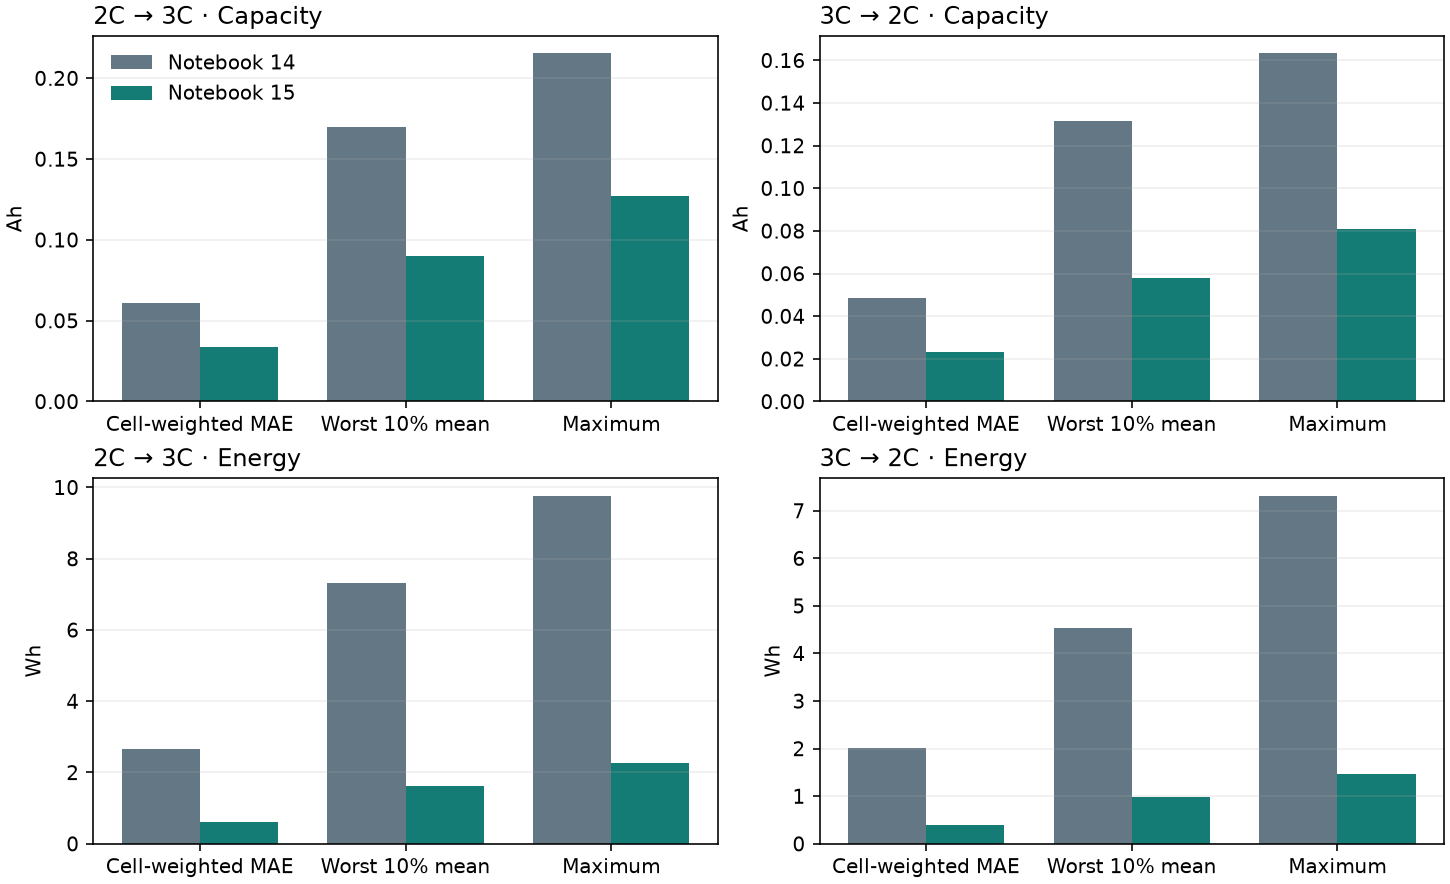

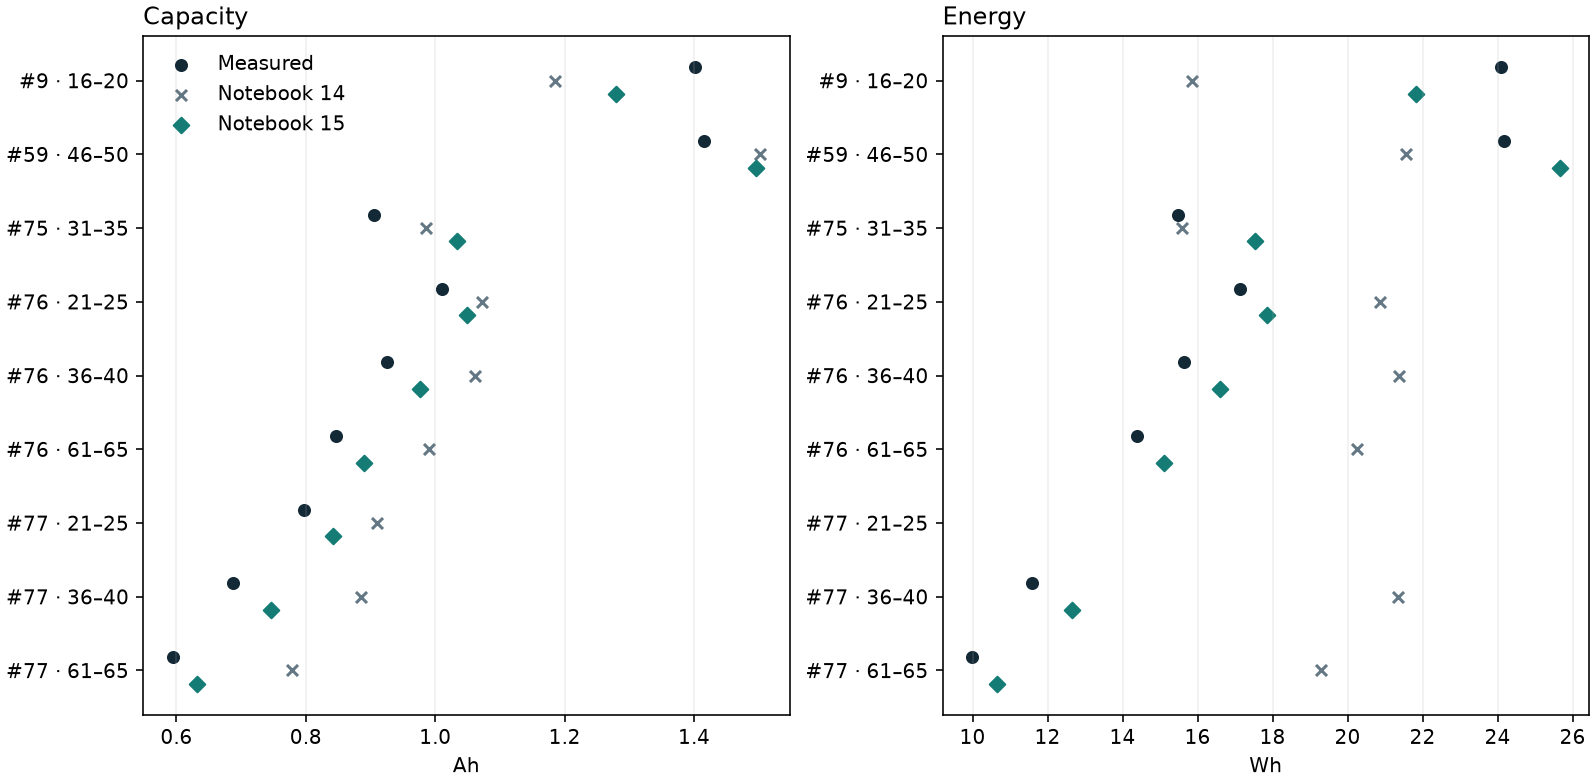

Saved /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP Final Project/reports/lifeguard_mit_bit_capacity_energy_results.zip


In [5]:
def plots():
    import matplotlib.pyplot as plt

    labels = ("Cell-weighted MAE", "Worst 10% mean", "Maximum")
    fields = ("mae", "worst_decile_mae", "max_error")
    comparison, panels = plt.subplots(2, 2, figsize=(10, 6.1), layout="constrained")
    index = metrics.set_index(["direction", "target", "model"])
    positions = np.arange(3)
    for target, axes in zip(TARGETS, panels):
        for direction, ax in zip(SWITCHES, axes):
            old, new = [index.loc[(direction, target, model)] for model in ("nb14", "nb15")]
            for row, shift, color, name in ((old, -0.19, "#647784", "Notebook 14"),
                                            (new, 0.19, "#147c74", "Notebook 15")):
                ax.bar(positions + shift, [row[field] for field in fields], width=0.38, color=color, label=name)
            ax.set_xticks(positions, labels)
            ax.set_title(direction.replace("-to-", "C → ") + "C · " + target.title(), loc="left")
            ax.set_ylabel(TARGETS[target]["unit"])
            ax.grid(axis="y", alpha=0.22)
    panels[0, 0].legend(frameon=False)
    comparison.savefig(output / "switch_errors.png", dpi=145)
    plt.close(comparison)

    figure, axes = plt.subplots(1, 2, figsize=(11, 5.4), layout="constrained")
    ordered = cases.sort_values(["cell_id", "start_cycle"])
    labels = [f"#{int(row.cell_id)} · {int(row.start_cycle)}–{int(row.end_cycle)}"
              for row in ordered.itertuples()]
    y = np.arange(len(labels))
    for target, ax in zip(TARGETS, axes):
        spec = TARGETS[target]
        for field, shift, symbol, color, name in (
            (spec["measured"], -0.18, "o", "#132936", "Measured"),
            (spec["baseline"], 0.0, "x", "#647784", "Notebook 14"),
            (spec["predicted"], 0.18, "D", "#147c74", "Notebook 15"),
        ):
            visible = ordered[f"{target}_paired"].to_numpy() & ordered[field].notna().to_numpy()
            ax.scatter(ordered[field].to_numpy()[visible], y[visible] + shift, marker=symbol,
                       color=color, s=30, label=name)
        ax.set_yticks(y, labels)
        ax.invert_yaxis()
        ax.set_xlabel(spec["unit"])
        ax.set_title(target.title(), loc="left")
        ax.grid(axis="x", alpha=0.2)
    axes[0].legend(loc="best", frameon=False)
    figure.savefig(output / "error_cases.png", dpi=145)
    plt.close(figure)


def pair_text(old, new, field):
    return f"{old[field]:.3f} → {new[field]:.3f}"


def summary():
    index = metrics.set_index(["direction", "target", "model"])
    total = checks.passed.sum()
    lines = [
        "# MIT–BIT charging switches — Capacity and energy forecast", "",
        "## বাংলা সারাংশ", "",
        f"একই held-out split-এ **{predictions.cell_id.nunique()}টি ব্যাটারির {len(predictions)}টি ব্লক** "
        "forecast করেছি। Ah ও Wh-এর ভুল Notebook 14-এর history-aware model-এর সঙ্গে একই scored row-তে তুলনা করা হয়েছে।",
        "",
        "| Rate বদল | মেট্রিক | গড় ভুল | সবচেয়ে ভুল ১০%-এর গড় | সর্বোচ্চ ভুল | Scored / eligible |",
        "| --- | --- | ---: | ---: | ---: | ---: |",
    ]
    for direction in SWITCHES:
        for target, spec in TARGETS.items():
            old, new = [index.loc[(direction, target, model)] for model in ("nb14", "nb15")]
            values = " | ".join(pair_text(old, new, field) for field in ("mae", "worst_decile_mae", "max_error"))
            lines.append(f"| {direction} | {spec['unit']} | {values} | {int(new.scored_blocks)}/{int(new.eligible_blocks)} |")

    event = predictions.loc[predictions.cell_id.eq(77) & predictions.start_cycle.eq(36)].iloc[0]
    lines += [
        "",
        f"Benchmark গ্রহণের শর্ত **{total}/{len(checks)}** তুলনায় পূরণ হয়েছে। #77-এর সাইকেল ৩৬–৪০-এ "
        f"capacity ভুল {abs(event.nb14_ah-event.observed_ah):.3f} → {abs(event.predicted_ah-event.observed_ah):.3f} Ah "
        f"এবং energy ভুল {abs(event.nb14_wh-event.observed_wh):.3f} → {abs(event.predicted_wh-event.observed_wh):.3f} Wh।",
        "",
        "এই পরীক্ষা MIT–BIT-এ recorded action-এর পরের পাঁচ সাইকেল নিয়ে। "
        "নতুন dataset-এ যাচাই ও controller benchmark পরের ধাপ।",
        "",
        "## Held-out metrics", "",
        "MAE and bias give equal weight to each battery. The worst-decile mean uses the largest "
        "ceil(10% × scored blocks) absolute errors. Bias is forecast minus measured. "
        "Capacity is the median of five measured discharge capacities. Energy is the sum of five "
        "meter-checked discharge energies. The nominal percentage columns use a fixed 2.4 Ah denominator.",
        "",
        "| Group | Unit | MAE old → new | Worst-decile mean old → new | Max old → new | New bias | Blocks | New worst location |",
        "| --- | --- | ---: | ---: | ---: | ---: | ---: | --- |",
    ]
    for direction in GROUPS:
        for target, spec in TARGETS.items():
            old, new = [index.loc[(direction, target, model)] for model in ("nb14", "nb15")]
            values = " | ".join(pair_text(old, new, field) for field in ("mae", "worst_decile_mae", "max_error"))
            location = f"#{int(new.worst_cell)} · {int(new.worst_start_cycle)}–{int(new.worst_end_cycle)}"
            lines.append(f"| {direction} | {spec['unit']} | {values} | {new.signed_bias:+.3f} | "
                         f"{int(new.scored_blocks)} | {location} |")

    stress = sensitivity.set_index(["first_rate_c", "target", "model"])
    lines += [
        "", "## Sensitivity to the first recorded charging rate", "",
        "Hold out all batteries with the specified first rate and score the two switch directions together. "
        "Both models are refitted on the same other batteries. This comparison uses the Notebook 14 "
        "feature set with alpha 1 and the 75:25 candidate with alpha 1 in each Ridge component.",
        "",
        "| First rate | Unit | MAE old → new | Worst-decile mean old → new | Max old → new | Scored blocks |",
        "| --- | --- | ---: | ---: | ---: | ---: |",
    ]
    for rate in RATES:
        for target, spec in TARGETS.items():
            old, new = [stress.loc[(rate, target, model)] for model in ("nb14", "nb15")]
            values = " | ".join(pair_text(old, new, field) for field in ("mae", "worst_decile_mae", "max_error"))
            lines.append(f"| {rate}C | {spec['unit']} | {values} | {int(new.scored_blocks)} |")
    lines.extend(["", "## Reproducibility", "",
                  "Selection uses the four inner fold predictions within each outer training set. "
                  "The inner score averages the two switch directions equally. "
                  "Each direction uses weights 0.50 for MAE, 0.35 for worst-decile mean, and 0.15 for maximum error.",
                  "",
                  "The saved MIT–BIT cohort was also used during exploration. "
                  "The results assess this cohort and serve as a baseline for a separate dataset."])
    return "\n".join(lines) + "\n"


output.mkdir(parents=True, exist_ok=True)
tables = {"predictions.csv": predictions, "metrics.csv": metrics, "model_selection.csv": selection,
          "first_rate_sensitivity.csv": sensitivity, "acceptance.csv": checks, "error_cases.csv": cases}
for name, frame in tables.items():
    frame.to_csv(output / name, index=False)
report_text = summary()
(output / "summary.md").write_text(report_text, encoding="utf-8")
with threadpool_limits(limits=1):
    plots()
settings = {
    "dataset_doi": "10.17632/kw34hhw7xg.3", "source": SOURCE_NAME,
    "source_exports": FILES, "nominal_ah": NOMINAL_AH, "block_cycles": BLOCK, "folds": 5,
    "ridge_alphas": ALPHAS, "expanded_weight_in_blend": BLEND_WEIGHT,
    "inner_score_weights": {"mae": 0.50, "worst_decile_mae": 0.35, "max_error": 0.15},
    "scored_cells": int(predictions.cell_id.nunique()), "acceptance_pass": bool(checks.passed.all()),
}
(output / "run_config.json").write_text(json.dumps(settings, indent=2) + "\n", encoding="utf-8")
archive = output.with_suffix(".zip")
with ZipFile(archive, "w", compression=ZIP_DEFLATED) as zip_result:
    for name in (*tables, "summary.md", "run_config.json", "switch_errors.png", "error_cases.png"):
        zip_result.write(output / name, name)

from IPython import get_ipython
from IPython.display import Image, Markdown, display

if get_ipython() is not None:
    display(Markdown(report_text))
    display(Image(filename=str(output / "switch_errors.png")))
    display(Image(filename=str(output / "error_cases.png")))
print(f"Saved {archive}")